In [366]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

In [367]:
df=pd.read_csv('mtsamples.csv')

In [368]:
df

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."
...,...,...,...,...,...,...
4994,4994,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN
4995,4995,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun..."
4996,4996,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN
4997,4997,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN


In [369]:
df['description'][0]

' A 23-year-old white female presents with complaint of allergies.'

In [370]:
df['keywords'].nunique()

3849

In [371]:
df['medical_specialty'].value_counts()

medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

In [372]:
df['medical_specialty'].unique()

array([' Allergy / Immunology', ' Bariatrics',
       ' Cardiovascular / Pulmonary', ' Neurology', ' Dentistry',
       ' Urology', ' General Medicine', ' Surgery', ' Speech - Language',
       ' SOAP / Chart / Progress Notes', ' Sleep Medicine',
       ' Rheumatology', ' Radiology', ' Psychiatry / Psychology',
       ' Podiatry', ' Physical Medicine - Rehab',
       ' Pediatrics - Neonatal', ' Pain Management', ' Orthopedic',
       ' Ophthalmology', ' Office Notes', ' Obstetrics / Gynecology',
       ' Neurosurgery', ' Nephrology', ' Letters',
       ' Lab Medicine - Pathology', ' IME-QME-Work Comp etc.',
       ' Hospice - Palliative Care', ' Hematology - Oncology',
       ' Gastroenterology', ' ENT - Otolaryngology', ' Endocrinology',
       ' Emergency Room Reports', ' Discharge Summary',
       ' Diets and Nutritions', ' Dermatology',
       ' Cosmetic / Plastic Surgery', ' Consult - History and Phy.',
       ' Chiropractic', ' Autopsy'], dtype=object)

In [373]:
df = df.drop(df[df['medical_specialty'].isin([' Allergy / Immunology', ' Bariatrics',  ' Dentistry',
          ' Speech - Language',
        ' Sleep Medicine',
       ' Rheumatology',  ' Psychiatry / Psychology',
       ' Podiatry', ' Physical Medicine - Rehab',
       ' Pediatrics - Neonatal', ' Pain Management', ' Orthopedic',
       ' Ophthalmology', ' Office Notes', 
        ' Nephrology', ' Letters',
       ' Lab Medicine - Pathology', ' IME-QME-Work Comp etc.',
       ' Hospice - Palliative Care', ' Hematology - Oncology',
         ' Endocrinology',
       ' Emergency Room Reports', 
       ' Diets and Nutritions', ' Dermatology',
       ' Cosmetic / Plastic Surgery',' Chiropractic',' Autopsy',' Neurosurgery',' ENT - Otolaryngology',' Discharge Summary',' Neurology',' SOAP / Chart / Progress Notes',' Obstetrics / Gynecology',' Urology'])].index)

In [374]:
df['medical_specialty'].value_counts()

medical_specialty
Surgery                       1103
Consult - History and Phy.     516
Cardiovascular / Pulmonary     372
Radiology                      273
General Medicine               259
Gastroenterology               230
Name: count, dtype: int64

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, ' Cardiovascular / Pulmonary'),
  Text(1, 0, ' General Medicine'),
  Text(2, 0, ' Surgery'),
  Text(3, 0, ' Radiology'),
  Text(4, 0, ' Gastroenterology'),
  Text(5, 0, ' Consult - History and Phy.')])

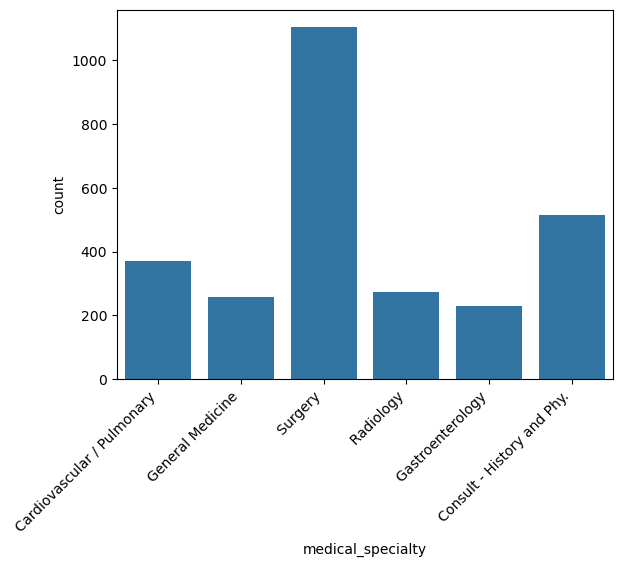

In [375]:
sns.countplot(df,x=df['medical_specialty'])
plt.xticks(rotation=45, ha='right')


In [376]:
df['transcription'].value_counts()

transcription
HISTORY OF PRESENT ILLNESS: , Mr. A is a 50-year-old gentleman with a history of atrial fibrillation in the past, more recently who has had atrial flutter, who estimates he has had six cardioversions since 10/09, and estimates that he has had 12 to 24 in his life beginning in 2006 when the atrial fibrillation first emerged.  He, since 10:17 p.m. on 01/17/10, noted recurrence of his atrial fibrillation, called our office this morning, that is despite being on flecainide, atenolol, and he is maintained on Coumadin.,The patient has noted some lightheadedness as well as chest discomfort and shortness of breath when atrial flutter recurred and we see that on his 12-lead EKG here.  Otherwise, no chest pain.,PAST MEDICAL HISTORY: , Significant for atrial fibrillation/atrial flutter and again he had atrial fibrillation more persistently in 2006, but more recently it has been atrial flutter and that is despite use of antiarrhythmics including flecainide.  He completed a stress tes

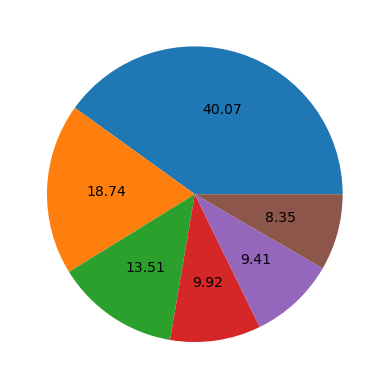

In [377]:
plt.pie(df['medical_specialty'].value_counts(),autopct = '%0.2f')
plt.show()

In [378]:
df.drop(columns=['Unnamed: 0', 'description',  'sample_name',
        'keywords'],inplace=True)
       

In [379]:
df

,medical_specialty,transcription
3,Cardiovascular / Pulmonary,"2-D M-MODE: , ,1. Left atrial enlargement wit..."
4,Cardiovascular / Pulmonary,1. The left ventricular cavity size and wall ...
7,Cardiovascular / Pulmonary,"2-D ECHOCARDIOGRAM,Multiple views of the heart..."
9,Cardiovascular / Pulmonary,"DESCRIPTION:,1. Normal cardiac chambers size...."
11,Cardiovascular / Pulmonary,"2-D STUDY,1. Mild aortic stenosis, widely calc..."
...,...,...
4972,Cardiovascular / Pulmonary,"INDICATION: , Chest pain.,TYPE OF TEST: , Aden..."
4973,Cardiovascular / Pulmonary,"CHIEF COMPLAINT: , Chest pain.,HISTORY OF PRES..."
4974,Cardiovascular / Pulmonary,"HISTORY OF PRESENT ILLNESS: , The patient is a..."
4975,Cardiovascular / Pulmonary,"HISTORY OF PRESENT ILLNESS: , Mr. ABC is a 60-..."


In [380]:
from sklearn.preprocessing import LabelEncoder

In [381]:
le=LabelEncoder()

In [382]:
df['medical_specialty']=le.fit_transform(df['medical_specialty'])

In [383]:
df

,medical_specialty,transcription
3,0,"2-D M-MODE: , ,1. Left atrial enlargement wit..."
4,0,1. The left ventricular cavity size and wall ...
7,0,"2-D ECHOCARDIOGRAM,Multiple views of the heart..."
9,0,"DESCRIPTION:,1. Normal cardiac chambers size...."
11,0,"2-D STUDY,1. Mild aortic stenosis, widely calc..."
...,...,...
4972,0,"INDICATION: , Chest pain.,TYPE OF TEST: , Aden..."
4973,0,"CHIEF COMPLAINT: , Chest pain.,HISTORY OF PRES..."
4974,0,"HISTORY OF PRESENT ILLNESS: , The patient is a..."
4975,0,"HISTORY OF PRESENT ILLNESS: , Mr. ABC is a 60-..."


In [384]:
df['medical_specialty'].value_counts()

medical_specialty
5    1103
1     516
0     372
4     273
3     259
2     230
Name: count, dtype: int64

In [385]:
df

,medical_specialty,transcription
3,0,"2-D M-MODE: , ,1. Left atrial enlargement wit..."
4,0,1. The left ventricular cavity size and wall ...
7,0,"2-D ECHOCARDIOGRAM,Multiple views of the heart..."
9,0,"DESCRIPTION:,1. Normal cardiac chambers size...."
11,0,"2-D STUDY,1. Mild aortic stenosis, widely calc..."
...,...,...
4972,0,"INDICATION: , Chest pain.,TYPE OF TEST: , Aden..."
4973,0,"CHIEF COMPLAINT: , Chest pain.,HISTORY OF PRES..."
4974,0,"HISTORY OF PRESENT ILLNESS: , The patient is a..."
4975,0,"HISTORY OF PRESENT ILLNESS: , Mr. ABC is a 60-..."


In [386]:
df.isna().sum()

medical_specialty     0
transcription        22
dtype: int64

In [387]:
df.duplicated().sum()

np.int64(19)

In [388]:
df.dropna(inplace=True)

In [389]:
df.isna().sum()

medical_specialty    0
transcription        0
dtype: int64

In [390]:
df.drop_duplicates(keep='first',inplace=True)

In [391]:
df.duplicated().sum()

np.int64(0)

In [392]:
df.rename(columns={'medical_specialty':'label','transcription':'text'},inplace=True)

In [393]:
df

,label,text
3,0,"2-D M-MODE: , ,1. Left atrial enlargement wit..."
4,0,1. The left ventricular cavity size and wall ...
7,0,"2-D ECHOCARDIOGRAM,Multiple views of the heart..."
9,0,"DESCRIPTION:,1. Normal cardiac chambers size...."
11,0,"2-D STUDY,1. Mild aortic stenosis, widely calc..."
...,...,...
4972,0,"INDICATION: , Chest pain.,TYPE OF TEST: , Aden..."
4973,0,"CHIEF COMPLAINT: , Chest pain.,HISTORY OF PRES..."
4974,0,"HISTORY OF PRESENT ILLNESS: , The patient is a..."
4975,0,"HISTORY OF PRESENT ILLNESS: , Mr. ABC is a 60-..."


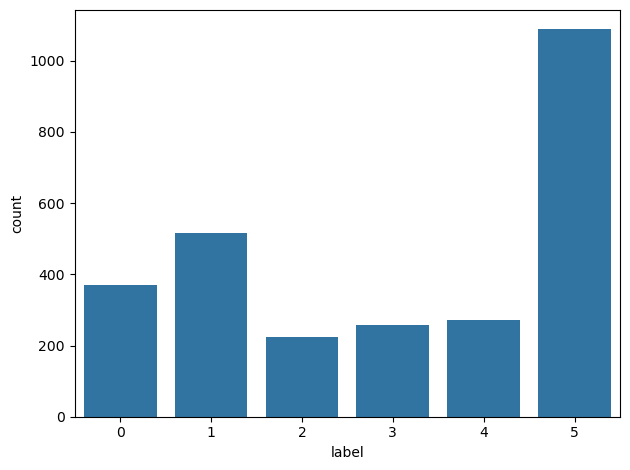

In [394]:
sns.countplot(df,x=df['label'])
plt.tight_layout()

In [395]:
import nltk
from nltk.corpus import stopwords

In [396]:
stop_words = set(stopwords.words('english'))

In [397]:
med_noise={'patient', 'dictated', 'transcribed', 'noted', 'unremarkable',
    'assessment', 'history', 'physical', 'clinic', 'hospital',
    'within', 'normal', 'limits', 'heent', 'signed'}

In [398]:
stop_words.update(med_noise)

In [399]:
stop_words

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'assessment',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'clinic',
 'couldn',
 "couldn't",
 'd',
 'dictated',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'heent',
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'history',
 'hospital',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'limits',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',

In [400]:
from nltk.stem import WordNetLemmatizer

In [401]:
def change(x):
    text=re.sub(r"[^a-zA-Z0-9]",' ',x).split()
    words=[y.lower() for y in text if y not in stop_words]
    le=WordNetLemmatizer()
    d=[le.lemmatize(word) for word in words]
    final=' '.join(d)
    return final
    

In [402]:
df['text']=df['text'].apply(change)

In [403]:
df['text']

3       2 d m mode 1 left atrial enlargement left atri...
4       1 the left ventricular cavity size wall thickn...
7       2 d echocardiogram multiple view heart great v...
9       description 1 normal cardiac chamber size 2 no...
11      2 d study 1 mild aortic stenosis widely calcif...
                              ...                        
4972    indication chest pain type of test adenosine n...
4973    chief complaint chest pain history of present ...
4974    history of present illness the 68 year old wom...
4975    history of present illness mr abc 60 year old ...
4976    reason for consultation abnormal echocardiogra...
Name: text, Length: 2731, dtype: object

In [404]:
X=df['text']
y=df['label']

In [405]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [406]:
vector=TfidfVectorizer(max_features=3000,min_df=5,max_df=0.8,ngram_range=(1, 2))

In [407]:
X=vector.fit_transform(X).toarray()

In [408]:
X

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.02382982, 0.        , 0.        , ..., 0.        , 0.02820837,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.05451313, 0.        ,
        0.        ]])

In [409]:
from sklearn.model_selection import train_test_split

In [410]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=100,stratify=y)

In [411]:
X_train.shape

(2184, 3000)

In [412]:
X_test.shape

(547, 3000)

In [413]:
from sklearn.svm import LinearSVC

In [414]:
su=LinearSVC(C=0.1,class_weight='balanced')

In [415]:
su.fit(X_train,y_train)

LinearSVC(C=0.1, class_weight='balanced')

In [416]:
su.score(X_train,y_train)

0.7527472527472527

In [417]:
y_predict=su.predict(X_test)

In [418]:
from sklearn import metrics

In [419]:
metrics.accuracy_score(y_test,y_predict)

0.6197440585009141

In [421]:
print(metrics.classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.39      0.39      0.39        74
           1       0.60      0.76      0.67       103
           2       0.40      0.49      0.44        45
           3       0.36      0.27      0.31        52
           4       0.62      0.76      0.68        55
           5       0.86      0.71      0.77       218

    accuracy                           0.62       547
   macro avg       0.54      0.56      0.54       547
weighted avg       0.64      0.62      0.62       547



<Axes: >

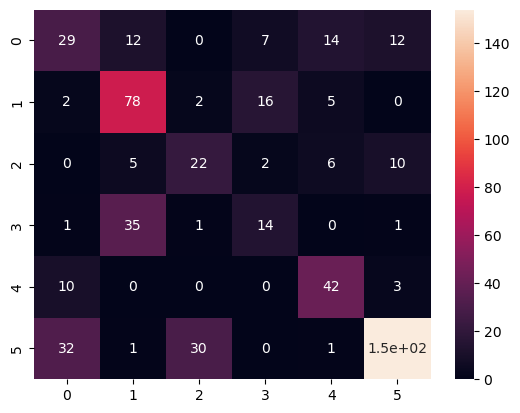

In [424]:
sns.heatmap(metrics.confusion_matrix(y_test,y_predict),annot=True)